# Анализ поездок такси (taxi.parquet)

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_parquet('C:/Users/mifan/PycharmProjects/AI/15_taxi.parquet')
print("Размер:", df.shape)
print("Период:", df['lpep_pickup_datetime'].min(), '-', df['lpep_pickup_datetime'].max())
df.head()

Размер: (56551, 20)
Период: 2023-12-31 14:38:47 - 2024-01-31 23:57:29


,VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,store_and_fwd_flag,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,extra,mta_tax,tip_amount,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge
0,2,2024-01-01 00:46:55,2024-01-01 00:58:25,N,1.0,236,239,1.0,1.98,12.8,1.0,0.5,3.61,0.0,NaN,1.0,21.66,1.0,1.0,2.75
1,2,2024-01-01 00:31:42,2024-01-01 00:52:34,N,1.0,65,170,5.0,6.54,30.3,1.0,0.5,7.11,0.0,NaN,1.0,42.66,1.0,1.0,2.75
2,2,2024-01-01 00:30:21,2024-01-01 00:49:23,N,1.0,74,262,1.0,3.08,19.8,1.0,0.5,3.00,0.0,NaN,1.0,28.05,1.0,1.0,2.75
3,1,2024-01-01 00:30:20,2024-01-01 00:42:12,N,1.0,74,116,1.0,2.40,14.2,1.0,1.5,0.00,0.0,NaN,1.0,16.70,2.0,1.0,0.00
4,2,2024-01-01 00:32:38,2024-01-01 00:43:37,N,1.0,74,243,1.0,5.14,22.6,1.0,0.5,6.28,0.0,NaN,1.0,31.38,1.0,1.0,0.00


56 551 поездка зелёного такси Нью-Йорка за январь 2024. 20 колонок:
* VendorID - код поставщика
* lpep_pickup_datetime - время начала
* lpep_dropoff_datetime - время конца
* store_and_fwd_flag - сохранить и переслать флаг
* RatecodeID - код тарифа
* PULocationID - зона посадки
* DOLocationID - зона высадки
* passenger_count - число пассажиров
* trip_distance - расстояние
* fare_amount - тариф по счётчику
* extra - надбавки
* mta_tax - налог MTA
* tip_amount - чаевые
* tolls_amount - платные дороги
* ehail_fee - комиссия за e-hail
* improvement_surcharge - сбор на развитие транспорта
* total_amount - итоговая сумма
* payment_type - тип оплаты
* trip_type - тип вызова
* congestion_surcharge - сбор за пробки

Пропуски:
 VendorID                     0
lpep_pickup_datetime         0
lpep_dropoff_datetime        0
store_and_fwd_flag        3415
RatecodeID                3415
PULocationID                 0
DOLocationID                 0
passenger_count           3415
trip_distance                0
fare_amount                  0
extra                        0
mta_tax                      0
tip_amount                   0
tolls_amount                 0
ehail_fee                56551
improvement_surcharge        0
total_amount                 0
payment_type              3415
trip_type                 3418
congestion_surcharge      3415
dtype: int64

Дубликатов: 0


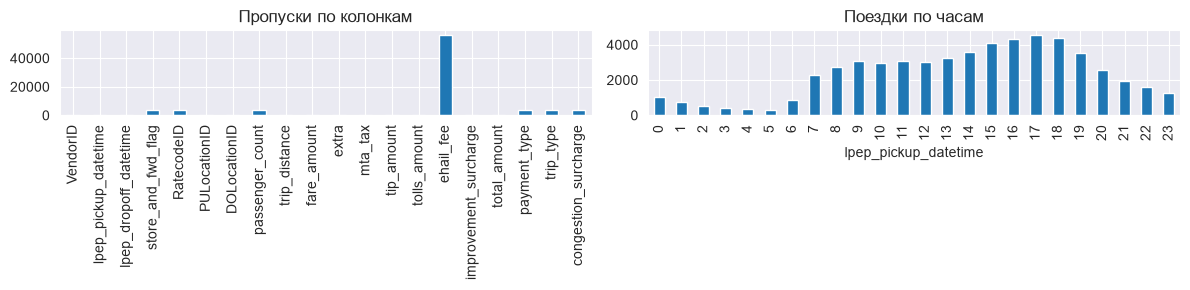

In [20]:
print("Пропуски:\n", df.isna().sum())
print("\nДубликатов:", df.duplicated().sum())
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
df.isna().sum().plot.bar(ax=ax[0], title='Пропуски по колонкам')
df['lpep_pickup_datetime'].dt.hour.value_counts().sort_index().plot.bar(ax=ax[1], title='Поездки по часам')
plt.tight_layout(); plt.show()

count    56551.00
mean        18.17
std         75.46
min          0.00
1%           0.07
50%         11.40
95%         33.68
99%         59.82
max       1438.98
Name: duration_min, dtype: float64
Удалено: 7611 строк (13.5%), осталось 48940


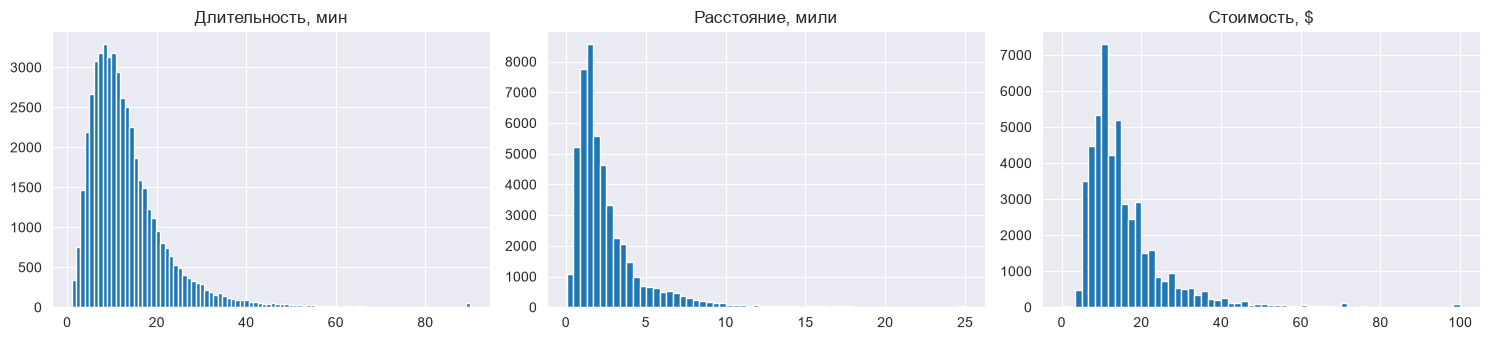

In [21]:
df['duration_min'] = (df['lpep_dropoff_datetime'] - df['lpep_pickup_datetime']).dt.total_seconds() / 60
print(df['duration_min'].describe(percentiles=[.01, .5, .95, .99]).round(2))

n0 = len(df)
df = df.drop(columns=['ehail_fee', 'store_and_fwd_flag']) # пустая и бесполезная
df = df.dropna(subset=['passenger_count', 'RatecodeID', 'trip_type', 'payment_type'])
mask = (df['duration_min'].between(1, 180) # не секунды и не сутки
        & df['trip_distance'].between(0.05, 100) # мили
        & df['fare_amount'].between(0, 500)
        & df['passenger_count'].between(1, 6)
        & df['PULocationID'].between(1, 265) & df['DOLocationID'].between(1, 265))
df = df[mask].copy()
print(f"Удалено: {n0 - len(df)} строк ({(n0-len(df))/n0:.1%}), осталось {len(df)}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist(df['duration_min'].clip(0, 90), bins=90); ax[0].set_title('Длительность, мин')
ax[1].hist(df['trip_distance'].clip(0, 25), bins=60); ax[1].set_title('Расстояние, мили')
ax[2].hist(df['fare_amount'].clip(0, 100), bins=60); ax[2].set_title('Стоимость, $')
plt.tight_layout(); plt.show()

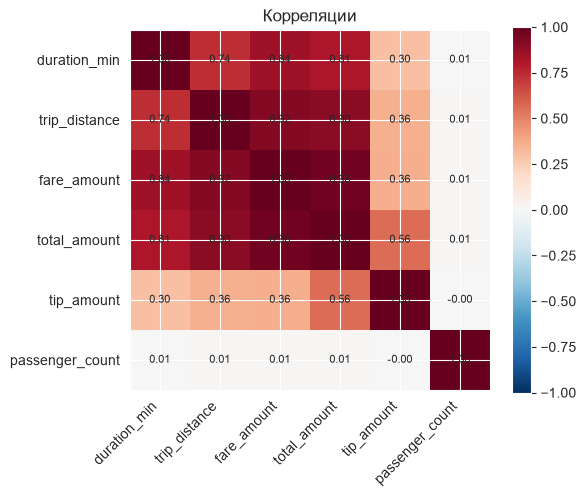

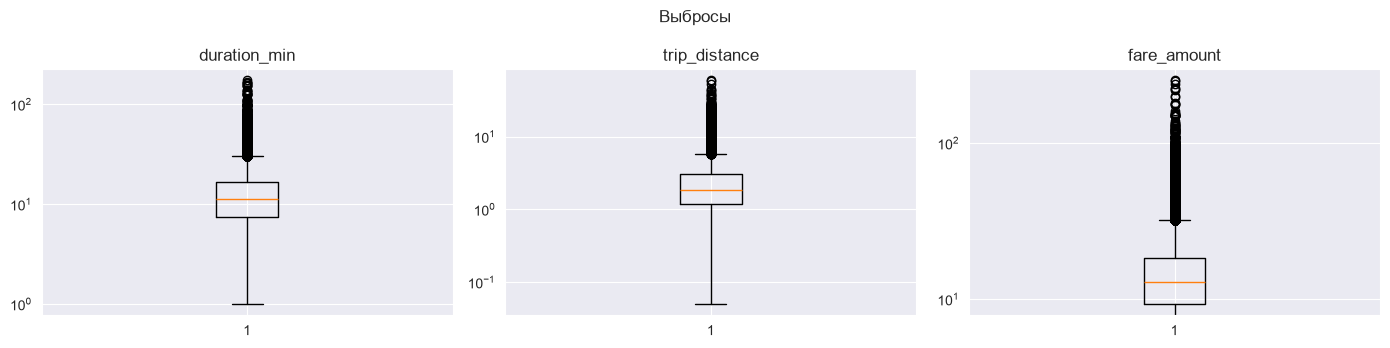

In [22]:
num_cols = ['duration_min', 'trip_distance', 'fare_amount', 'total_amount', 'tip_amount', 'passenger_count']
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=45, ha='right')
ax.set_yticks(range(len(num_cols)), num_cols)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im); plt.title('Корреляции'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, c in zip(ax, ['duration_min', 'trip_distance', 'fare_amount']):
    a.boxplot(df[c]); a.set_title(c); a.set_yscale('log')
plt.suptitle('Выбросы'); plt.tight_layout(); plt.show()

Пропуски сосредоточены в служебных полях (passenger_count, payment_type, RatecodeID, trip_type, congestion_surcharge) - примерно в 6% строк, и это одни и те же поездки. Восстановить эти факты из других колонок я посчитал некорректным - тип оплаты и число пассажиров не вычисляются. Поэтому я удалил эти 3415 поездок: потеря 6% не влияет на выводы. Колонку ehail_fee удалил целиком - она пустая на 100%.

Это регрессия: предсказываю total_amount 0 сколько водитель заработает с поездки. Беру только то, что известно до начала поездки: зоны посадки и высадки, час, день недели, число пассажиров, тип заказа, тариф и способ оплаты. Расстояние по счётчику (trip_distance) и все суммы-компоненты (fare_amount, tip_amount и т.д.) в признаки не беру - они известны только в конце поездки, и модель просто списала бы тарифную формулу.
Дополнительно кластеризую зоны посадки, а в конце найду самые выгодные часы и зоны

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tr, te = train_test_split(df, test_size=0.2, random_state=42)

# Частоты считаем по обучению, иначе утечка
pu_freq = tr.groupby('PULocationID').size()
route_freq = tr.groupby(['PULocationID', 'DOLocationID']).size()

def make_feats(part):
    F = pd.DataFrame(index=part.index)
    F['hour'] = part['lpep_pickup_datetime'].dt.hour
    F['dow'] = part['lpep_pickup_datetime'].dt.day_of_week
    F['passengers'] = part['passenger_count'].fillna(1)
    F['pu_zone'] = part['PULocationID']
    F['do_zone'] = part['DOLocationID']
    F['vendor'] = part['VendorID']
    F['trip_type'] = part['trip_type'].fillna(1)
    F['ratecode'] = part['RatecodeID'].fillna(1)
    F['payment'] = part['payment_type'].fillna(1)      # 1=карта, 2=наличные
    F['pu_freq'] = part['PULocationID'].map(pu_freq).fillna(0)
    idx = pd.MultiIndex.from_arrays([part['PULocationID'], part['DOLocationID']])
    F['route_freq'] = route_freq.reindex(idx).fillna(0).values
    return F

base = ['hour','dow','passengers','pu_zone','do_zone','vendor','trip_type','ratecode','payment']
good = base + ['pu_freq', 'route_freq']

Xtr, Xte = make_feats(tr), make_feats(te)
ytr, yte = tr['total_amount'], te['total_amount']
print("Признаки:", good)

def evaluate(name, model, cols):
    model.fit(Xtr[cols], ytr)
    p = model.predict(Xte[cols])
    return {'модель': name, 'MAE ($)': mean_absolute_error(yte, p),
            'RMSE ($)': np.sqrt(mean_squared_error(yte, p)), 'R2': r2_score(yte, p)}

res = pd.DataFrame([
    evaluate('Среднее значение', DummyRegressor(), base),
    evaluate('Линейная регрессия', LinearRegression(), base),
    evaluate('Случайный лес (300)', RandomForestRegressor(300, random_state=42, n_jobs=-1), base),
])
print(res.round(3).to_string(index=False))

# Модель для ручного ввода и графиков
final_rf = RandomForestRegressor(300, min_samples_leaf=2, random_state=42, n_jobs=-1).fit(Xtr[good], ytr)

Признаки: ['hour', 'dow', 'passengers', 'pu_zone', 'do_zone', 'vendor', 'trip_type', 'ratecode', 'payment', 'pu_freq', 'route_freq']
             модель  MAE ($)  RMSE ($)     R2
   Среднее значение    9.002    13.835 -0.000
 Линейная регрессия    8.458    13.232  0.085
Случайный лес (300)    4.484     8.903  0.586


Предсказывать заработок средним значением бесполезно: ошибка 9.00 долларов, R2 = 0. Линейная регрессия чуть лучше (R2 = 0.085, ошибка 8.46) тк номера зон это коды, а не числа. Случайный лес заметно лучше: R2 = 0.586, средняя ошибка 4.48 доллара с поездки (RMSE 8.90). То есть заработок до посадки оценивается с точностью до 4-5 долларов. R2 = 0.586 значит, что модель объясняет около 59% разброса сумм. Остальное - чаевые (решение человека) и точное расстояние, которого до поездки мы не знаем.

In [30]:
def predict_trip(pu_zone, do_zone, when='2024-01-15 18:00:00', passengers=1, payment=1):
    row = pd.DataFrame([{'lpep_pickup_datetime': pd.to_datetime(when),
                         'PULocationID': pu_zone, 'DOLocationID': do_zone,
                         'passenger_count': passengers, 'VendorID': 2,
                         'trip_type': 1.0, 'RatecodeID': 1.0, 'payment_type': payment}])
    p = final_rf.predict(make_feats(row))[0]
    pay = 'карта' if payment == 1 else 'наличные'
    print(f"Зона {pu_zone} - зона {do_zone}, {when}, {pay}: прогноз заработка ${p:.2f}")
    return p

predict_trip(74, 236, '2024-01-15 18:00:00', payment=1)   # час пик, карта
predict_trip(74, 236, '2024-01-15 03:00:00', payment=1)   # ночь
predict_trip(74, 236, '2024-01-15 18:00:00', payment=2)   # наличные

Зона 74 - зона 236, 2024-01-15 18:00:00, карта: прогноз заработка $21.36
Зона 74 - зона 236, 2024-01-15 03:00:00, карта: прогноз заработка $16.97
Зона 74 - зона 236, 2024-01-15 18:00:00, наличные: прогноз заработка $18.54


np.float64(18.538017394179892)

Можно ввести зоны, время, число пассажиров и способ оплаты модель выдаёт прогноз заработка. Один и тот же маршрут картой предсказывается дороже, чем наличными: при наличных чаевые в данных не записаны, но это не значит, что наличные хуже для водителя - просто датасет их не видит.

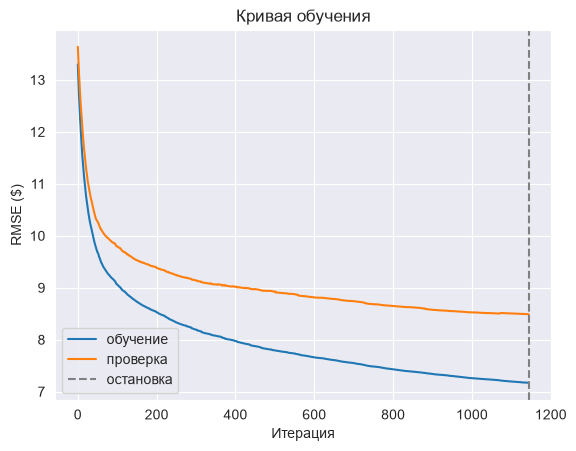

Деревьев построено: 1145 | RMSE на проверке: 8.49


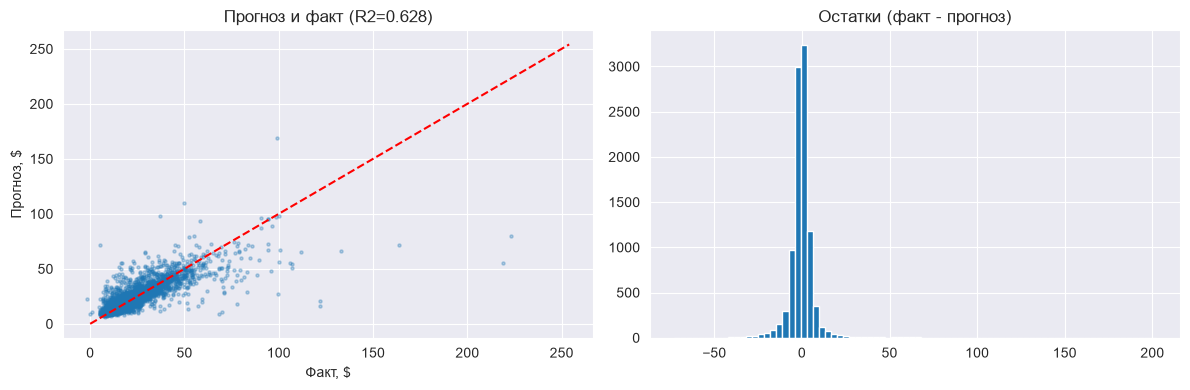

In [38]:
# Кривая обучения
gb = GradientBoostingRegressor(n_estimators=3000, learning_rate=0.05, max_depth=3,
                               validation_fraction=0.1, n_iter_no_change=20, tol=1e-4,
                               random_state=42).fit(Xtr[good], ytr)
tr_rmse = [np.sqrt(mean_squared_error(ytr, p)) for p in gb.staged_predict(Xtr[good])]
te_rmse = [np.sqrt(mean_squared_error(yte, p)) for p in gb.staged_predict(Xte[good])]
plt.plot(tr_rmse, label='обучение'); plt.plot(te_rmse, label='проверка')
plt.axvline(len(te_rmse)-1, ls='--', c='gray', label='остановка')
plt.xlabel('Итерация'); plt.ylabel('RMSE ($)'); plt.legend()
plt.title('Кривая обучения'); plt.show()
print("Деревьев построено:", gb.n_estimators_, "| RMSE на проверке:", round(te_rmse[-1], 2))

# Прогноз и факт + остатки
pred = final_rf.predict(Xte[good])
s = np.random.RandomState(42).choice(len(yte), min(5000, len(yte)), replace=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(yte.iloc[s], pred[s], s=5, alpha=.3)
lims = [0, max(yte.max(), pred.max())]
ax[0].plot(lims, lims, 'r--'); ax[0].set_xlabel('Факт, $'); ax[0].set_ylabel('Прогноз, $')
ax[0].set_title(f'Прогноз и факт (R2={r2_score(yte, pred):.3f})')
ax[1].hist(yte - pred, bins=80); ax[1].set_title('Остатки (факт - прогноз)')
plt.tight_layout(); plt.show()

Кривая остановилась на 1145 деревьях — это и есть предел, дальше качество не растёт.
На графике прогноз-факт точки лежат вдоль диагонали, остатки около нуля — систематического смещения нет. Дорогие поездки модель занижает: таких примеров мало.

Зон с >=50 поездками: 43


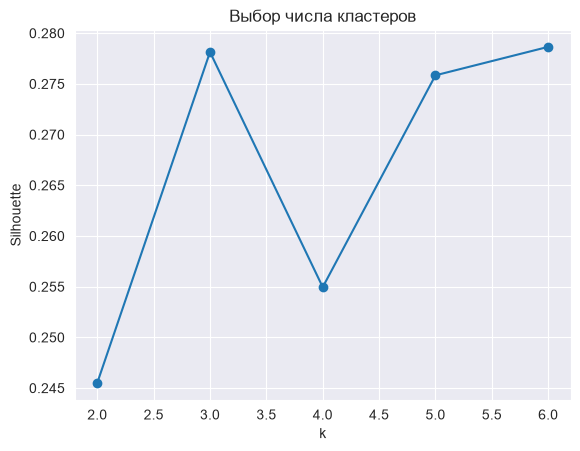

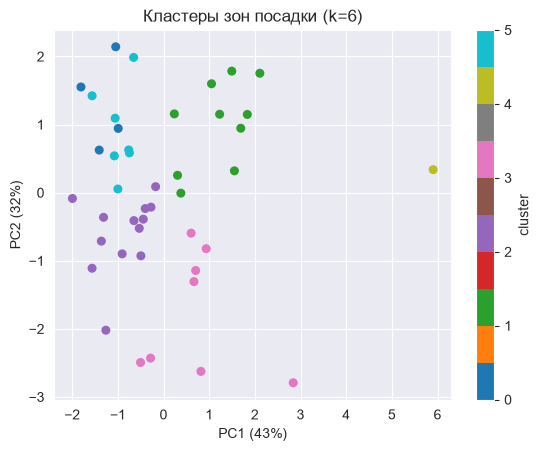

         n_trips  total_med  dur_med  dist_med  earn_per_min  tip_share
cluster                                                                
0        6192.00      18.28    10.55      1.75          1.76       0.75
1         292.40      26.35    14.97      3.25          1.74       0.76
2        1294.31      17.18    11.39      1.93          1.58       0.50
3         142.25      21.89    14.29      2.90          1.50       0.33
4          66.00      59.12    30.12      9.09          1.82       0.48
5         284.57      15.82     9.06      1.52          1.83       0.65


In [25]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

df['tipped'] = df['tip_amount'] > 0
df['earn_per_min'] = df['total_amount'] / df['duration_min']

zones = df.groupby('PULocationID').agg(
    n_trips=('total_amount', 'size'),
    total_med=('total_amount', 'median'),
    dur_med=('duration_min', 'median'),
    dist_med=('trip_distance', 'median'),
    earn_per_min=('earn_per_min', 'median'),
    tip_share=('tipped', 'mean'))
zones = zones[zones['n_trips'] >= 50]          # только надёжные зоны
print("Зон с >=50 поездками:", len(zones))

feat = pd.DataFrame({'log_n': np.log1p(zones['n_trips']),
                     'log_total': np.log1p(zones['total_med']),
                     'earn_per_min': zones['earn_per_min'],
                     'dur_med': zones['dur_med'],
                     'tip_share': zones['tip_share']})
Xc = StandardScaler().fit_transform(feat)

sil = {k: silhouette_score(Xc, KMeans(k, n_init=10, random_state=42).fit(Xc).labels_) for k in range(2, 7)}
plt.plot(list(sil), list(sil.values()), 'o-'); plt.xlabel('k'); plt.ylabel('Silhouette')
plt.title('Выбор числа кластеров'); plt.show()

k = max(sil, key=sil.get)
km = KMeans(k, n_init=10, random_state=42).fit(Xc)
zones['cluster'] = km.labels_
pca = PCA(2, random_state=42); XY = pca.fit_transform(Xc)
plt.scatter(XY[:, 0], XY[:, 1], c=zones['cluster'], cmap='tab10', s=30)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
plt.title(f'Кластеры зон посадки (k={k})'); plt.colorbar(label='cluster'); plt.show()
print(zones.groupby('cluster')[['n_trips','total_med','dur_med','dist_med','earn_per_min','tip_share']].mean().round(2))

43 зоны посадки разделились на 6 групп.
* 0 - самые загруженные: 6192 поездки на зону, короткие (10.5 мин), чек 18.28, чаевые 75%.
* 1 - поездки длиннее (15 мин, 3.25 мили), чек 26.35, чаевые 76% — максимум, но поездок всего 292.
* 2 - похож на кластер 0 по поездкам, но чаевые 50% и доходность ниже: 1.58 против 1.76.
* 3 - худшая доходность (1.50) и чаевые 33%, при этом поездки не короткие (14.3 мин).
* 4 - дальние и дорогие: 66 поездок, 30 мин / 9 миль, чек 59.12.
* 5 - самые короткие и дешёвые (9 мин, чек 15.82), зато лучшая доходность на минуту (1.83).
В итоге за минуту платят почти везде одинаково, поэтому заработок за смену решает число поездок без простоев - это группы 0 и 2. Но чаевые тут посчитаны по всем поездкам, а наличные не записываются, поэтому 33% и 76% - это в основном разница в доле оплат картой, а не в щедрости.

Бустинг: деревьев построено 1145
                  модель  MAE ($)  RMSE ($)    R2
      Лес leaf=2, mf=0.5    4.197     8.428 0.629
 Лес + частоты маршрутов    4.222     8.442 0.628
      Лес leaf=2, mf=1.0    4.222     8.442 0.628
  Без vendor и trip_type    4.223     8.457 0.626
      Без способа оплаты    4.315     8.459 0.626
Бустинг (авто-остановка)    4.397     8.491 0.623
      Лес leaf=5, mf=0.5    4.234     8.505 0.622
         Лес + log(цель)    4.062     8.511 0.622
      Лес leaf=5, mf=1.0    4.208     8.522 0.621
      Лес leaf=1, mf=0.5    4.316     8.525 0.620
      Лес leaf=1, mf=1.0    4.343     8.566 0.617
   Лес, простые признаки    4.484     8.903 0.586
Быстрый бустинг (HistGB)    4.952     9.096 0.568


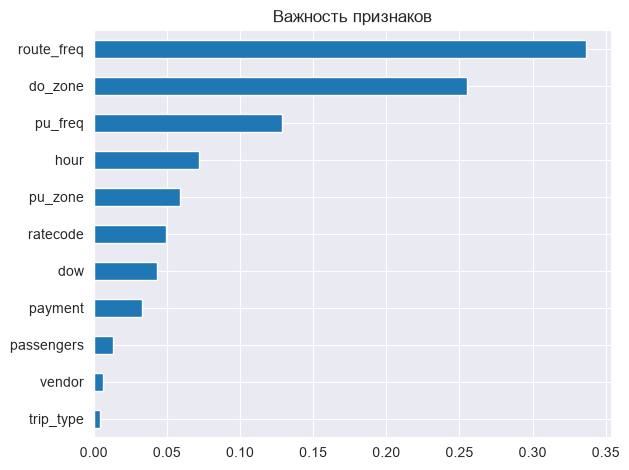

In [37]:
rows = []
def add_row(name, p):
    rows.append([name, mean_absolute_error(yte, p),
                 np.sqrt(mean_squared_error(yte, p)), r2_score(yte, p)])

# 1) Простые признаки
m = RandomForestRegressor(300, random_state=42, n_jobs=-1).fit(Xtr[base], ytr)
add_row('Лес, простые признаки', m.predict(Xte[base]))

# 2) + частоты зон и маршрутов
add_row('Лес + частоты маршрутов', final_rf.predict(Xte[good]))

# 3) Логарифм цели — только положительные суммы (в данных есть возвраты)
pos = ytr > 0
m = RandomForestRegressor(300, min_samples_leaf=2, random_state=42, n_jobs=-1).fit(Xtr[good][pos], np.log1p(ytr[pos]))
add_row('Лес + log(цель)', np.expm1(m.predict(Xte[good])))

# 4) Перебор параметров леса
for leaf in [1, 2, 5]:
    for mf in [0.5, 1.0]:
        m = RandomForestRegressor(300, min_samples_leaf=leaf, max_features=mf,
                                  random_state=42, n_jobs=-1).fit(Xtr[good], ytr)
        add_row(f'Лес leaf={leaf}, mf={mf}', m.predict(Xte[good]))

# 5) Бустинг с авто-остановкой (считается несколько минут)
gb_auto = GradientBoostingRegressor(n_estimators=3000, learning_rate=0.05, max_depth=3,
                                    validation_fraction=0.1, n_iter_no_change=20, tol=1e-4,
                                    random_state=42).fit(Xtr[good], ytr)
print("Бустинг: деревьев построено", gb_auto.n_estimators_)
add_row('Бустинг (авто-остановка)', gb_auto.predict(Xte[good]))

# 6) Быстрый бустинг — тоже с авто-остановкой, считается заметно быстрее
hgb = HistGradientBoostingRegressor(max_iter=1500, learning_rate=0.06, max_depth=3,
                                    l2_regularization=1.0, early_stopping=True,
                                    random_state=42).fit(Xtr[good], ytr)
add_row('Быстрый бустинг (HistGB)', hgb.predict(Xte[good]))

# 7) Без способа оплаты — насколько важны чаевые
no_pay = [c for c in good if c != 'payment']
m = RandomForestRegressor(300, min_samples_leaf=2, random_state=42, n_jobs=-1).fit(Xtr[no_pay], ytr)
add_row('Без способа оплаты', m.predict(Xte[no_pay]))

# 8) Без слабых признаков
simple = [c for c in good if c not in ['vendor', 'trip_type']]
m = RandomForestRegressor(300, min_samples_leaf=2, random_state=42, n_jobs=-1).fit(Xtr[simple], ytr)
add_row('Без vendor и trip_type', m.predict(Xte[simple]))

table = pd.DataFrame(rows, columns=['модель', 'MAE ($)', 'RMSE ($)', 'R2']).sort_values('RMSE ($)')
print(table.round(3).to_string(index=False))

pd.Series(final_rf.feature_importances_, index=good).sort_values().plot.barh()
plt.title('Важность признаков'); plt.tight_layout(); plt.show()

Перебрал 13 вариантов. Лучший — случайный лес с min_samples_leaf=2 и max_features=0.5
* Частоты маршрутов вместе с настройкой листьев подняли R2 с 0.586 до 0.629.
* Логарифм цели снизил среднюю ошибку до 4.06, но RMSE сделал хуже: лог точнее на обычных поездках и хуже на дорогих.
* Бустинг с авто-остановкой: 1145 деревьев, MAE 4.40, RMSE 8.49, R2 0.623 - чуть хуже леса.
* Без способа оплаты: 4.32 / 8.46 / 0.626 - почти не изменилось. Оплата влияет на отдельные маршруты, но не на общую точность.
* Без vendor и trip_type: 4.22 / 8.46 / 0.626 - то же самое, эти признаки можно выкинуть.

Топ часов по итоговой оценке:
                       trips  earn_per_min  total_med  dur_med  tip_share_card  \
lpep_pickup_datetime                                                            
19                     3214         1.870     18.750   10.350           0.926   
18                     3980         1.767     19.260   11.117           0.944   
17                     4122         1.701     19.680   11.750           0.935   
20                     2376         1.825     17.000    9.750           0.931   
16                     3848         1.673     19.475   11.817           0.925   
22                     1423         1.852     16.700    9.583           0.911   
21                     1774         1.817     17.160    9.850           0.893   
23                     1124         1.850     16.450    9.483           0.881   

                      score  
lpep_pickup_datetime         
19                    0.896  
18                    0.792  
17                    0.729  
20      

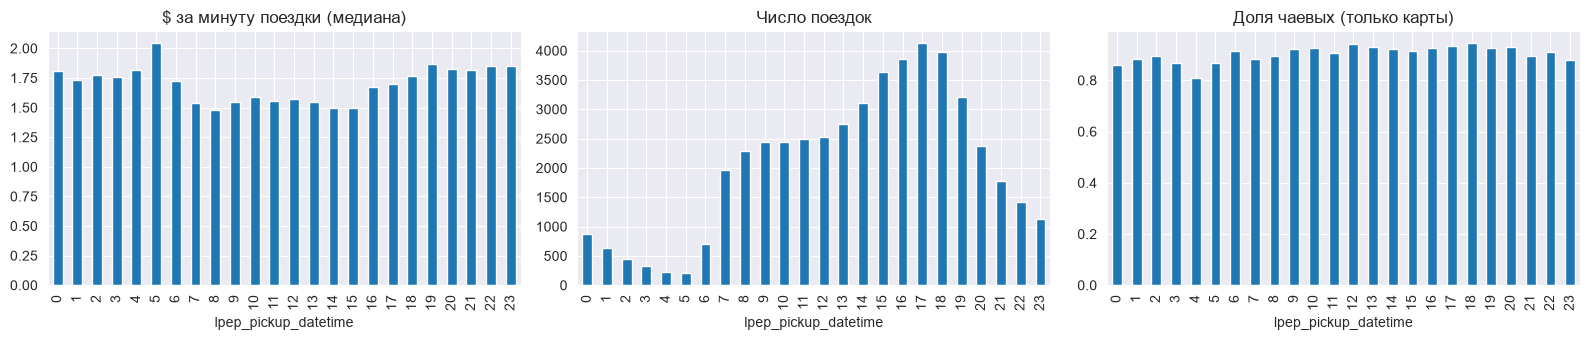


Топ зон по $/мин:
               trips  earn_per_min  total_med  dur_med  score
PULocationID                                                
210             165          1.94      13.40     6.95   0.61
236             308          1.92      18.42     9.32   0.67
80              136          1.92      29.30    14.56   0.53
43             2695          1.90      19.43    10.18   0.93
223             310          1.88      15.96     8.87   0.64
75             7992          1.84      17.16     9.28   0.91
112             101          1.84      29.76    17.42   0.43
244            1136          1.83      30.90    16.13   0.74
179             123          1.82      14.43     8.95   0.43
33              351          1.80      21.00    13.18   0.60

Топ зон по итоговой оценке:
               trips  earn_per_min  total_med  dur_med  score
PULocationID                                                
43             2695          1.90      19.43    10.18   0.93
75             7992          1.84  

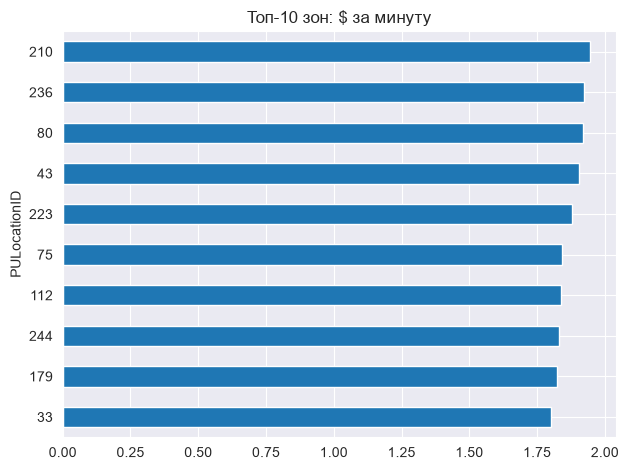

In [27]:
g = df.groupby(df['lpep_pickup_datetime'].dt.hour)
by_hour = g.agg(trips=('earn_per_min', 'size'),
                earn_per_min=('earn_per_min', 'median'),
                total_med=('total_amount', 'median'),
                dur_med=('duration_min', 'median'))
# чаевые считаем только по картам
by_hour['tip_share_card'] = df[df['payment_type'] == 1].groupby(
    df['lpep_pickup_datetime'].dt.hour)['tipped'].mean()
by_hour['score'] = (by_hour['earn_per_min'].rank(pct=True) + by_hour['trips'].rank(pct=True)) / 2
print("Топ часов по итоговой оценке:\n", by_hour.round(3).sort_values('score', ascending=False).head(8))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
by_hour['earn_per_min'].plot.bar(ax=ax[0], title='$ за минуту поездки (медиана)')
by_hour['trips'].plot.bar(ax=ax[1], title='Число поездок')
by_hour['tip_share_card'].plot.bar(ax=ax[2], title='Доля чаевых (только карты)')
plt.tight_layout(); plt.show()

by_zone = df.groupby('PULocationID').agg(trips=('earn_per_min', 'size'),
                                         earn_per_min=('earn_per_min', 'median'),
                                         total_med=('total_amount', 'median'),
                                         dur_med=('duration_min', 'median'))
by_zone = by_zone[by_zone['trips'] >= 100].copy()
by_zone['score'] = (by_zone['earn_per_min'].rank(pct=True) + by_zone['trips'].rank(pct=True)) / 2
print("\nТоп зон по $/мин:\n", by_zone.sort_values('earn_per_min', ascending=False).head(10).round(2))
print("\nТоп зон по итоговой оценке:\n", by_zone.sort_values('score', ascending=False).head(10).round(2))

by_zone['earn_per_min'].sort_values(ascending=False).head(10).plot.barh(title='Топ-10 зон: $ за минуту')
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

Самый выгодный час - 19:00:
Вечер выгоднее дня: в 16-17 часов поездок больше всего (3848 и 4122), но доходность самая низкая (1.67 и 1.70) и поездки самые длинные (11.8 мин) - пробки. К 19-23 часам поездки короче (9.5-10.4 мин), а доходность выше (1.82-1.87). Чаевые по картам почти везде одинаковые (88–94%), время суток на щедрость не влияет.
Лучшие зоны по итоговой оценке - 43 и 75. Самая загруженная зона 74 имеет низкую доходность 1.59 - много поездок не значит выгодно.